# Yearly raster time series, Mann-Kendall Tau, and STANDARD

The calculation flow is: create an ordered in-memory raster group from separate annual files, prepare the yearly time series and per-year NaN masks, calculate Mann-Kendall Tau, then apply STANDARD to the Tau image. A histogram review of the Tau and standardized-Tau distributions is the final step. The notebook does not classify results; it writes the standardized Tau raster that the downstream classification step consumes.

In [10]:
### Import Packages ###
from pathlib import Path
import math, multiprocessing, os, re
import numpy as np
import rasterio
from rasterio.enums import Resampling
from rasterio.windows import Window
#from tqdm.auto import tqdm  # progress bars (notebook widget in Jupyter)

In [12]:
### Filename helper ###

def get_year(filename):
    """Extract a four-digit year from names such as ``1990_area_1km.tif``."""
    filename = Path(filename).name
    match = re.search(r"(?<!\d)((?:19|20)\d{2})(?!\d)", filename)
    if not match:
        raise ValueError(
            f"Could not extract a four-digit year from {filename!r}. "
            "Expected a name such as '1990_area_1km.tif'."
        )
    return int(match.group(1))


def get_ordered_input_files(input_dir, input_pattern):
    """Find yearly rasters and sort them by the four-digit year in each name."""
    input_paths = list(Path(input_dir).glob(input_pattern))
    if not input_paths:
        raise FileNotFoundError(f"No rasters match {Path(input_dir) / input_pattern}")
    keyed_paths = [(get_year(path.name), path) for path in input_paths]
    keyed_paths.sort(key=lambda item: (item[0], item[1].name.lower()))
    years = [year for year, _ in keyed_paths]
    if len(years) != len(set(years)):
        raise ValueError("More than one input raster matched for a year; narrow input_pattern to one raster per year")
    return [path for _, path in keyed_paths]



def build_workflow_paths(main_workspace, metric_type):
    """Build the fixed input and output paths from the workspace and metric."""
    workspace = Path(main_workspace)
    input_dir = workspace / "3_MovingWindow" / f"mw_{metric_type}"
    input_pattern = f"*_{metric_type}_1km.tif"
    analysis_dir = workspace / "4_TS_and_TI"
    return {
        "input_dir": input_dir,
        "input_pattern": input_pattern,
        "tau_path": analysis_dir / "TS" / metric_type / f"{metric_type}_raster_group_MK_tau.tif",
        "mask_nan_dir": analysis_dir / "TS_mask" / f"{metric_type}_mask",
        "standardized_tau_path": analysis_dir / "TS_zscore" / metric_type / f"{metric_type}_MK_tau_z.tif",
    }



def validate_parameters(main_workspace, metric_type, min_observations,
                        multiprocessing_workers, tile_rows, tile_cols):
    """Check user-selected settings before starting raster processing."""
    # The workspace root must already exist. Do not create it: a missing
    # main_workspace is a setup error, and auto-creating it would silently
    # make empty output trees at an unintended location (e.g. a stray
    # Windows-style path inside a Linux container).
    if not Path(main_workspace).is_dir():
        raise FileNotFoundError(
            f"main_workspace does not exist or is not a directory: {main_workspace}. "
            "Create or mount it before running; it is not created automatically."
        )
    if metric_type not in {"area", "edge", "pn"}:
        raise ValueError("metric_type must be 'area', 'edge', or 'pn'")
    if min_observations < 2:
        raise ValueError("min_observations must be at least 2")
    if multiprocessing_workers < 1 or tile_rows < 1 or tile_cols < 1:
        raise ValueError("multiprocessing_workers, tile_rows, and tile_cols must be positive")



def validate_zero_nodata_semantics(sources):
    """Reject ambiguous inputs that declare zero as NoData without a mask.

    A separate per-dataset or alpha mask can distinguish valid zeros from
    missing cells. If zero is the only NoData signal, those meanings cannot
    be recovered reliably from pixel values alone.
    """
    for source in sources:
        flags = {flag.name for flag in source.mask_flag_enums[0]}
        has_explicit_mask = bool({"per_dataset", "alpha"} & flags)
        if source.nodata == 0 and "nodata" in flags and not has_explicit_mask:
            raise ValueError(
                f"{source.name} declares 0 as NoData without a separate validity mask. "
                "Valid zeros and missing cells would be indistinguishable. "
                "Encode missing cells as NaN or a nonzero NoData value, or provide "
                "an explicit raster validity mask before running this workflow."
            )


### Parameters

Edit the project workspace, metric, and processing settings here. Input and output folders follow the project's fixed folder structure and are built by a helper function below.

In [54]:
### Parameters ###

# Project and metric
main_workspace = "./data"  # Path(r"D:\GitHub\typology\data")
metric_type = "pn"  # Choose: "area", "edge", or "pn"

# Mann-Kendall settings
min_observations = 10  # Editable Python cutoff: minimum valid years required per pixel

# --- Memory & performance (tune these) -------------------------------------
# Heavy raster work is processed in square block_size x block_size tiles and
# written as *tiled* GeoTIFFs, so peak memory depends on block_size (a value
# you choose), not on the image width.

ram_fraction = 0.90   # fraction of the max RAM the job may use
cpu_fraction = 0.80   # fraction of logical CPUs for Stage 3 workers
block_size = 512      # GeoTIFF tile size AND processing block (multiple of 16)
gdal_cache_mb = 512   # cap on GDAL's block cache (MB) - stops runaway memory

use_multiprocessing = True

# Cap GDAL's block cache once, before any raster is opened. This is the main
# memory fix: without it, GDAL's decompressed-block cache grows until the
# process swaps or is killed. Spawn workers set the same cap themselves.
os.environ["GDAL_CACHEMAX"] = str(gdal_cache_mb)

if block_size % 16 != 0 or block_size < 16:
    raise ValueError("block_size must be a positive multiple of 16 (GeoTIFF requirement)")

available_cores = os.cpu_count() or 1
multiprocessing_workers = (
    max(1, math.floor(available_cores * cpu_fraction)) if use_multiprocessing else 1
)
tile_rows = block_size
tile_cols = block_size

print(f"Workers: {multiprocessing_workers} of {available_cores} cores "
      f"({cpu_fraction:.0%}); tile {block_size} x {block_size}; "
      f"GDAL cache cap {gdal_cache_mb} MB")

Workers: 19 of 24 cores (80%); tile 512 x 512; GDAL cache cap 512 MB


In [55]:
### Build fixed input and output paths ###

validate_parameters(
    main_workspace, metric_type, min_observations,
    multiprocessing_workers, tile_rows, tile_cols
)
workflow_paths = build_workflow_paths(main_workspace, metric_type)
input_files = get_ordered_input_files(
    workflow_paths["input_dir"], workflow_paths["input_pattern"]
)
print(f"Input folder: {workflow_paths['input_dir']}")
print(f"Matched yearly rasters: {len(input_files)}")
print(f"Years: {get_year(input_files[0].name)} - {get_year(input_files[-1].name)}")
print(f"Tau output: {workflow_paths['tau_path']}")
print(f"NaN masks: {workflow_paths['mask_nan_dir']}")
print(f"Standardized Tau: {workflow_paths['standardized_tau_path']}")
print(f"Metric: {metric_type}")
print(f"Multiprocessing: {use_multiprocessing}; workers: {multiprocessing_workers}; "
      f"tile size: {tile_rows} rows x {tile_cols} columns")

Input folder: data/3_MovingWindow/mw_pn
Matched yearly rasters: 31
Years: 1990 - 2020
Tau output: data/4_TS_and_TI/TS/pn/pn_raster_group_MK_tau.tif
NaN masks: data/4_TS_and_TI/TS_mask/pn_mask
Standardized Tau: data/4_TS_and_TI/TS_zscore/pn/pn_MK_tau_z.tif
Metric: pn
Multiprocessing: True; workers: 19; tile size: 512 rows x 512 columns


## Workflow stages and TerrSet-aligned choices

1. **Raster group and yearly series:** read the separate annual rasters in year order (`1990_area`, etc.). These are the observations for a metric; they are not separate MK outputs. Grid alignment is checked, and a per-year `mask_nan` file records missing cells (`1`) versus data (`0`). No stack or group manifest is written.
2. **Mann-Kendall Tau:** calculate one Tau image for the selected metric. The code uses `S / [n(n-1)/2]` over valid observation pairs; equal-valued pairs add zero to S. This is the Tau-only output. Significance Z/p, CMK, and Theil-Sen are not calculated.
3. **STANDARD(Tau):** apply `(Tau - valid-cell mean) / valid-cell standard deviation` to valid Tau cells. The divisor is `N` as selected here; the supplied TerrSet description does not specify `N` versus `N-1`.
4. **Histogram review:** inspect the raw Tau and standardized-Tau distributions, and view the chosen +/- threshold lines. This is a final review step; the notebook does not apply the threshold or recode the central range.

The supplied KENDALL notes require at least 10 observations for an appropriate result. The Python setting applies this minimum per pixel; the notes do not specify TerrSet's exact per-pixel missing-observation behavior. Inputs must distinguish valid zero from NoData. Missing values are excluded; a valid Tau of zero remains data. No classification is produced.

In [56]:
### Mann-Kendall worker import ###

# The per-tile Tau kernel lives in mk_calc_worker.py next to this notebook.
# Keeping it in a real importable module (rather than an embedded source
# string) lets the 'spawn' processes used on Windows/Docker import it directly.
# _init_worker_gdal_env is the pool initializer that caps GDAL's cache in each
# spawn worker.
import os, sys

if not any(os.path.exists(os.path.join(p, "mk_calc_worker.py")) for p in sys.path):
    for root, _dirs, files in os.walk(os.getcwd()):
        if "mk_calc_worker.py" in files:
            sys.path.insert(0, root)
            break

from mk_calc_worker import calculate_mk_for_tile, _init_worker_gdal_env

In [57]:
### Stage 1: create the raster group

def create_raster_group(input_paths, metric_type):
    """Create an ordered in-memory group from separate annual raster files.

    The returned object contains the paths, years, and band-style labels such
    as ``1990_area``. No manifest or raster data copy is written.
    """
    keyed_paths = [(get_year(Path(path).name), Path(path).resolve()) for path in input_paths]
    keyed_paths.sort(key=lambda item: (item[0], item[1].name.lower()))
    ordered_paths = [path for _, path in keyed_paths]
    years = [year for year, _ in keyed_paths]
    if not ordered_paths:
        raise ValueError("At least one annual input raster is required")
    if len(years) != len(set(years)):
        raise ValueError("More than one raster was provided for a year")
    missing_paths = [path for path in ordered_paths if not path.is_file()]
    if missing_paths:
        raise FileNotFoundError(f"Raster group contains missing inputs: {missing_paths}")
    labels = [f"{year}_{metric_type}" for year in years]
    print(f"In-memory raster group contains {len(ordered_paths)} annual rasters")
    return {"input_paths": ordered_paths, "years": years,
            "time_series_labels": labels, "metric_type": metric_type}


def run_raster_group_stage():
    """Create the ordered annual raster group from the notebook parameters."""
    return create_raster_group(input_files, metric_type)

In [58]:
### Run Stage 1: create the raster group

raster_group_results = run_raster_group_stage()
print(f"Raster group contains {len(raster_group_results['input_paths'])} annual inputs")

In-memory raster group contains 31 annual rasters
Raster group contains 31 annual inputs


In [59]:
### Stage 2: prepare the yearly time series and NaN masks

def create_time_series(raster_group_results, mask_nan_dir, block_size):
    """Validate annual rasters and write a separate missing-data mask per year.

    The per-year masks are written as *tiled* GeoTIFFs and processed in square
    ``block_size`` x ``block_size`` windows, so peak memory depends on
    block_size rather than the image width. In each mask, 1 means missing/NaN
    and 0 means data is present, including valid zero.
    """
    input_paths = raster_group_results["input_paths"]
    years = raster_group_results["years"]
    if not input_paths:
        raise ValueError("The raster group contains no annual rasters")
    sources = [rasterio.open(path) for path in input_paths]
    mask_destinations = []
    try:
        validate_zero_nodata_semantics(sources)
        reference = sources[0]
        for path, source in zip(input_paths, sources):
            same_grid = ((source.width, source.height, source.transform, source.crs) ==
                         (reference.width, reference.height, reference.transform, reference.crs))
            if not same_grid:
                raise ValueError(f"Input raster grid differs from the first raster: {path}")

        mask_nan_dir = Path(mask_nan_dir)
        mask_nan_dir.mkdir(parents=True, exist_ok=True)
        mask_nan_paths = [mask_nan_dir / f"{raster_group_results['metric_type']}_{year}_mask_nan.tif"
                          for year in years]
        mask_profile = reference.profile.copy()
        # Tiled output: each block writes to its own GeoTIFF tile with no
        # read-modify-write, and later windowed reads touch only the blocks
        # they need. Square blocks match the processing window exactly.
        mask_profile.update(driver="GTiff", count=1, dtype="uint8", nodata=None,
                            compress="deflate", tiled=True,
                            blockxsize=block_size, blockysize=block_size)
        mask_destinations = [rasterio.open(path, "w", **mask_profile) for path in mask_nan_paths]

# new vresion use after add tqdm to docker
        # image_height, image_width = reference.height, reference.width
        # block_count = math.ceil(image_height / block_size) * math.ceil(image_width / block_size)

        # # Live progress bar over the tiles (shows %, count, elapsed, and ETA).
        # with tqdm(total=block_count, desc="Stage 2: NaN masks", unit="tile") as pbar:
        #     for row in range(0, image_height, block_size):
        #         block_height = min(block_size, image_height - row)
        #         for col in range(0, image_width, block_size):
        #             block_width = min(block_size, image_width - col)
        #             window = Window(col, row, block_width, block_height)
        #             for source, destination in zip(sources, mask_destinations):
        #                 values = source.read(1, window=window)
        #                 valid = (source.read_masks(1, window=window) > 0) & np.isfinite(values)
        #                 destination.write((~valid).astype(np.uint8), 1, window=window)
        #             pbar.update(1)
                    
        #old version of progress bar and writing masks
        image_height, image_width = reference.height, reference.width
        block_count = math.ceil(image_height / block_size) * math.ceil(image_width / block_size)
        progress_interval = max(1, block_count // 20)

        completed = 0
        for row in range(0, image_height, block_size):
            block_height = min(block_size, image_height - row)
            for col in range(0, image_width, block_size):
                block_width = min(block_size, image_width - col)
                window = Window(col, row, block_width, block_height)
                for source, destination in zip(sources, mask_destinations):
                    values = source.read(1, window=window)
                    valid = (source.read_masks(1, window=window) > 0) & np.isfinite(values)
                    destination.write((~valid).astype(np.uint8), 1, window=window)
                completed += 1
                if completed % progress_interval == 0 or completed == block_count:
                    print(f"NaN-mask tiles written: {completed:,}/{block_count:,}")
                    

        print(f"Per-year mask_nan rasters saved: {mask_nan_dir}")
        return {"input_paths": input_paths, "years": years,
                "time_series_labels": raster_group_results["time_series_labels"],
                "mask_nan_paths": mask_nan_paths, "profile": reference.profile.copy(),
                "metric_type": raster_group_results["metric_type"]}
    finally:
        for destination in mask_destinations:
            destination.close()
        for source in sources:
            source.close()


def run_time_series_stage(raster_group_results):
    """Prepare the yearly raster time series and create its NaN masks."""
    return create_time_series(
        raster_group_results=raster_group_results,
        mask_nan_dir=workflow_paths["mask_nan_dir"],
        block_size=block_size,
    )

In [60]:
### Run Stage 2: prepare the time series

time_series_results = run_time_series_stage(raster_group_results)
print(f"Prepared {len(time_series_results['time_series_labels'])} yearly inputs")
print(f"Created {len(time_series_results['mask_nan_paths'])} per-year NaN masks")

NaN-mask tiles written: 1,379/27,594
NaN-mask tiles written: 2,758/27,594
NaN-mask tiles written: 4,137/27,594
NaN-mask tiles written: 5,516/27,594
NaN-mask tiles written: 6,895/27,594
NaN-mask tiles written: 8,274/27,594
NaN-mask tiles written: 9,653/27,594
NaN-mask tiles written: 11,032/27,594
NaN-mask tiles written: 12,411/27,594
NaN-mask tiles written: 13,790/27,594
NaN-mask tiles written: 15,169/27,594
NaN-mask tiles written: 16,548/27,594
NaN-mask tiles written: 17,927/27,594
NaN-mask tiles written: 19,306/27,594
NaN-mask tiles written: 20,685/27,594
NaN-mask tiles written: 22,064/27,594
NaN-mask tiles written: 23,443/27,594
NaN-mask tiles written: 24,822/27,594
NaN-mask tiles written: 26,201/27,594
NaN-mask tiles written: 27,580/27,594
NaN-mask tiles written: 27,594/27,594
Per-year mask_nan rasters saved: data/4_TS_and_TI/TS_mask/pn_mask
Prepared 31 yearly inputs
Created 31 per-year NaN masks


In [61]:
### Stage 3: Mann-Kendall Tau

def merge_image_statistics(count_a, mean_a, m2_a, values):
    """Merge finite Tau values into whole-image mean and variance statistics."""
    valid_values = values[np.isfinite(values)].astype(np.float64, copy=False)
    count_b = valid_values.size
    if count_b == 0:
        return count_a, mean_a, m2_a
    mean_b = float(valid_values.mean())
    m2_b = float(np.square(valid_values - mean_b).sum())
    if count_a == 0:
        return count_b, mean_b, m2_b
    delta = mean_b - mean_a
    count = count_a + count_b
    mean = mean_a + delta * count_b / count
    m2 = m2_a + m2_b + delta * delta * count_a * count_b / count
    return count, mean, m2


def calculate_mann_kendall_tau(time_series_results, tau_path, min_observations,
                               use_multiprocessing, multiprocessing_workers,
                               block_size):
    """Calculate Tau from separate annual rasters and return image statistics.

    Processing uses square ``block_size`` x ``block_size`` tiles and writes a
    *tiled* GeoTIFF, so peak memory depends on block_size and the worker count
    rather than the image width. Each worker reads its own spatial window from
    every annual input. Pixels with fewer than ``min_observations`` valid years
    are written as NoData. Whole-image Tau population standard deviation is
    accumulated for STANDARD.
    """
    tile_worker = calculate_mk_for_tile
    input_paths = tuple(str(Path(path)) for path in time_series_results["input_paths"])
    tau_path = Path(tau_path)
    image_count = 0
    tau_mean = 0.0
    tau_m2 = 0.0
    pool = None

    sources = [rasterio.open(path) for path in input_paths]
    try:
        validate_zero_nodata_semantics(sources)
        reference = sources[0]
        image_height, image_width = reference.height, reference.width
        profile = reference.profile.copy()
        nodata_value = -9999.0  # Exported NoData marker; Tau values are limited to [-1, 1]
        # Tiled single-band output matching the square processing blocks.
        profile.update(count=1, dtype="float32", nodata=nodata_value,
                       compress="deflate", tiled=True,
                       blockxsize=block_size, blockysize=block_size)

        block_count = math.ceil(image_height / block_size) * math.ceil(image_width / block_size)
        worker_count = min(multiprocessing_workers, block_count)

        def tile_data():
            """Yield lightweight tile descriptors for worker-side reads."""
            for row in range(0, image_height, block_size):
                block_height = min(block_size, image_height - row)
                for col in range(0, image_width, block_size):
                    block_width = min(block_size, image_width - col)
                    window_offsets = (col, row, block_width, block_height)
                    yield row, col, window_offsets, input_paths, min_observations

        if use_multiprocessing and worker_count > 1:
            chunksize = max(1, block_count // (worker_count * 8))
            # Each spawn worker sets the same GDAL cache cap via an initializer,
            # so no worker reopens the inputs with an unbounded cache.
            pool = multiprocessing.get_context("spawn").Pool(
                processes=worker_count,
                initializer=_init_worker_gdal_env,
                initargs=(gdal_cache_mb,),
            )
            tile_results = pool.imap_unordered(tile_worker, tile_data(), chunksize=chunksize)
            print(f"Mann-Kendall processing with {worker_count} workers; chunksize {chunksize}")
        else:
            tile_results = map(tile_worker, tile_data())
            print("Mann-Kendall processing sequentially")

        completed_blocks = 0
        tau_path.parent.mkdir(parents=True, exist_ok=True)
        with rasterio.open(tau_path, "w", **profile) as tau_destination:
            for row, col, tau in tile_results:
                block_height, block_width = tau.shape
                window = Window(col, row, block_width, block_height)
                tau_destination.write(
                    np.where(np.isfinite(tau), tau, nodata_value).astype(np.float32),
                    1, window=window
                )
                image_count, tau_mean, tau_m2 = merge_image_statistics(
                    image_count, tau_mean, tau_m2, tau
                )
                completed_blocks += 1
                if completed_blocks % max(1, block_count // 20) == 0 or completed_blocks == block_count:
                    print(f"Mann-Kendall tiles: {completed_blocks:,}/{block_count:,}")

        if pool is not None:
            pool.close()
            pool.join()
            pool = None
        if image_count == 0:
            raise ValueError("No pixels met the minimum valid-year requirement")
        tau_std = math.sqrt(tau_m2 / image_count)
        return {"tau_path": tau_path, "tau_mean": tau_mean, "tau_std": tau_std,
                "valid_pixels": image_count, "profile": profile, "nodata": nodata_value}
    finally:
        if pool is not None:
            pool.terminate()
            pool.join()
        for source in sources:
            source.close()


def run_mann_kendall_tau_stage(time_series_results):
    """Run Tau analysis on the yearly raster inputs by spatial windows."""
    return calculate_mann_kendall_tau(
        time_series_results=time_series_results,
        tau_path=workflow_paths["tau_path"],
        min_observations=min_observations,
        use_multiprocessing=use_multiprocessing,
        multiprocessing_workers=multiprocessing_workers,
        block_size=block_size,
    )

In [62]:
### Run Stage 3: calculate Mann-Kendall Tau

mk_results = run_mann_kendall_tau_stage(time_series_results)
print(f"Mann-Kendall Tau raster: {mk_results['tau_path']}")
print(f"Whole-image Tau mean: {mk_results['tau_mean']:.6g}")
print(f"Whole-image Tau standard deviation: {mk_results['tau_std']:.6g}")
print(f"Valid Tau pixels: {mk_results['valid_pixels']:,}")

Mann-Kendall processing with 19 workers; chunksize 181
Mann-Kendall tiles: 1,379/27,594
Mann-Kendall tiles: 2,758/27,594
Mann-Kendall tiles: 4,137/27,594
Mann-Kendall tiles: 5,516/27,594
Mann-Kendall tiles: 6,895/27,594
Mann-Kendall tiles: 8,274/27,594
Mann-Kendall tiles: 9,653/27,594
Mann-Kendall tiles: 11,032/27,594
Mann-Kendall tiles: 12,411/27,594
Mann-Kendall tiles: 13,790/27,594
Mann-Kendall tiles: 15,169/27,594
Mann-Kendall tiles: 16,548/27,594
Mann-Kendall tiles: 17,927/27,594
Mann-Kendall tiles: 19,306/27,594
Mann-Kendall tiles: 20,685/27,594
Mann-Kendall tiles: 22,064/27,594
Mann-Kendall tiles: 23,443/27,594
Mann-Kendall tiles: 24,822/27,594
Mann-Kendall tiles: 26,201/27,594
Mann-Kendall tiles: 27,580/27,594
Mann-Kendall tiles: 27,594/27,594
Mann-Kendall Tau raster: data/4_TS_and_TI/TS/pn/pn_raster_group_MK_tau.tif
Whole-image Tau mean: 0.0555301
Whole-image Tau standard deviation: 0.36645
Valid Tau pixels: 1,033,913,254


In [63]:
### Stage 4: STANDARD(Tau)

def standardize_tau(mk_results, output_path, block_size):
    """Apply the TerrSet STANDARD formula to the Mann-Kendall Tau raster.

    Reads and writes in square ``block_size`` x ``block_size`` tiles to stay
    memory-bounded and to match the tiled Tau raster produced by Stage 3.
    """
    tau_mean = mk_results["tau_mean"]
    tau_std = mk_results["tau_std"]
    if tau_std == 0:
        raise ValueError("Tau standard deviation is zero; STANDARD cannot rescale a constant Tau image")
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    profile = mk_results["profile"].copy()
    nodata_value = mk_results["nodata"]
    image_height, image_width = profile["height"], profile["width"]
    with rasterio.open(mk_results["tau_path"]) as tau_source, \
         rasterio.open(output_path, "w", **profile) as standardized_destination:
        for row in range(0, image_height, block_size):
            block_height = min(block_size, image_height - row)
            for col in range(0, image_width, block_size):
                block_width = min(block_size, image_width - col)
                window = Window(col, row, block_width, block_height)
                tau = tau_source.read(1, window=window, masked=True).astype(np.float32).filled(np.nan)
                valid = np.isfinite(tau)
                standardized = np.full(tau.shape, nodata_value, dtype=np.float32)
                standardized[valid] = ((tau[valid] - tau_mean) / tau_std).astype(np.float32)
                standardized_destination.write(standardized, 1, window=window)
    print(f"STANDARD(Tau) saved: {output_path}")
    return Path(output_path)

In [64]:
### Run Stage 4: standardize Tau

standardized_tau_path = standardize_tau(
    mk_results, workflow_paths["standardized_tau_path"], block_size
)

STANDARD(Tau) saved: data/4_TS_and_TI/TS_zscore/pn/pn_MK_tau_z.tif


Recover stages if workers die after being completed


In [13]:
### Kernel-death recovery helpers ###

# The slow stages (2 and 3) already write their heavy outputs to disk as
# GeoTIFFs. If the kernel dies, only the in-memory dicts (time_series_results,
# mk_results) are lost -- not the files. These helpers rebuild those dicts from
# the files already on disk, so recovery takes seconds instead of re-running
# the stages. Run the "Recover ..." cells below the stage runners when needed.

def recover_time_series_results(main_workspace=None, metric_type=None):
    """Rebuild time_series_results from the input rasters and existing masks."""
    main_workspace = main_workspace if main_workspace is not None else globals()["main_workspace"]
    metric_type = metric_type if metric_type is not None else globals()["metric_type"]
    paths = build_workflow_paths(main_workspace, metric_type)
    input_files = get_ordered_input_files(paths["input_dir"], paths["input_pattern"])
    years = [get_year(p.name) for p in input_files]
    mask_nan_paths = [paths["mask_nan_dir"] / f"{metric_type}_{year}_mask_nan.tif"
                      for year in years]
    with rasterio.open(input_files[0]) as src:
        profile = src.profile.copy()
    missing = [p for p in mask_nan_paths if not Path(p).exists()]
    if missing:
        print(f"WARNING: {len(missing)} mask file(s) missing -- rerun Stage 2 if Tau is not done yet.")
    result = {"input_paths": input_files, "years": years,
              "time_series_labels": [f"{y}_{metric_type}" for y in years],
              "mask_nan_paths": mask_nan_paths, "profile": profile,
              "metric_type": metric_type}
    print(f"Recovered time_series_results: {len(input_files)} inputs, "
          f"years {years[0]}-{years[-1]}")
    return result


def recover_mk_results(main_workspace=None, metric_type=None):
    """Rebuild mk_results from the Tau raster already on disk.

    tau_mean and tau_std are recomputed with a streaming Welford pass over the
    saved Tau raster (block-by-block, memory-safe) -- far cheaper than redoing
    the full Mann-Kendall calculation.
    """
    main_workspace = main_workspace if main_workspace is not None else globals()["main_workspace"]
    metric_type = metric_type if metric_type is not None else globals()["metric_type"]
    tau_path = build_workflow_paths(main_workspace, metric_type)["tau_path"]
    if not Path(tau_path).exists():
        raise FileNotFoundError(
            f"Tau raster not found at {tau_path}; run Stage 3 before recovering mk_results.")
    count = 0
    mean = 0.0
    m2 = 0.0
    with rasterio.open(tau_path) as src:
        profile = src.profile.copy()
        nodata = src.nodata
        for _, window in src.block_windows(1):
            block = src.read(1, window=window, masked=True)
            values = np.ma.getdata(block)[~np.ma.getmaskarray(block)].astype(np.float64)
            if values.size:
                delta = values - mean
                count += values.size
                mean += delta.sum() / count
                m2 += ((values - mean) * delta).sum()
    if count == 0:
        raise ValueError("No valid Tau pixels found in the saved raster.")
    tau_std = (m2 / count) ** 0.5
    result = {"tau_path": Path(tau_path), "tau_mean": mean, "tau_std": tau_std,
              "valid_pixels": count, "profile": profile, "nodata": nodata}
    print(f"Recovered mk_results: mean={mean:.6g}, std={tau_std:.6g}, valid={count:,}")
    return result

In [42]:
# Stage 2
#### Recover `time_series_results` (run only if the kernel died)
### Rebuilds the dict from files on disk instead of re-running Stage 2.
### Recover time_series_results after a kernel restart ###
time_series_results = recover_time_series_results()
print(f"Prepared {len(time_series_results['time_series_labels'])} yearly inputs")

Recovered time_series_results: 31 inputs, years 1990-2020
Prepared 31 yearly inputs


In [22]:
# Stage 3
#### Recover `mk_results` (run only if the kernel died)
### Rebuilds the dict from the saved Tau raster instead of re-running Stage 3.
### Recover mk_results after a kernel restart ###
mk_results = recover_mk_results()
print(f"Tau mean {mk_results['tau_mean']:.6g}, std {mk_results['tau_std']:.6g}, "
      f"valid {mk_results['valid_pixels']:,}")

Recovered mk_results: mean=0.0569957, std=0.47733, valid=1,027,646,953
Tau mean 0.0569957, std 0.47733, valid 1,027,646,953


In [ ]:
# Stage 4
### Recover standardized_tau_path after a kernel restart ###
# Reads in the existing Stage 4 output instead of re-running Stage 4.
standardized_tau_path = workflow_paths["standardized_tau_path"]
if not Path(standardized_tau_path).exists():
    raise FileNotFoundError(f"Stage 4 output not found at {standardized_tau_path}; run Stage 4 first.")
print("Recovered standardized_tau_path:", standardized_tau_path)


Recovered standardized_tau_path: data/4_TS_and_TI/TS_zscore/edge/edge_MK_tau_z.tif


#### Recover `standardized_tau_path` (run only if the kernel died)
Just points at the Stage 4 output already on disk — no recomputation.

In [ ]:
### Recover standardized_tau_path after a kernel restart ###
# Reads in the existing Stage 4 output instead of re-running Stage 4.
# standardized_tau_path = workflow_paths["standardized_tau_path"]
# if not Path(standardized_tau_path).exists():
#     raise FileNotFoundError(f"Stage 4 output not found at {standardized_tau_path}; run Stage 4 first.")
# print("Recovered standardized_tau_path:", standardized_tau_path)

## Stage 5: typology classification threshold and histogram review

The `zscore_threshold` below is the standardized-Tau cutoff for the downstream typology classification (applied in a later step, not here). This notebook only uses it to draw the `+/-` reference lines on the histogram so you can see where the classification cut will fall against the distribution. Adjust the threshold, re-run the histogram, and inspect the lines. The histogram does not apply the threshold or modify any raster.

In [50]:
### Typology classification threshold (used by the downstream classification step) ###

# Standardized-Tau cutoff. The histogram below only displays this as +/- lines;
# the actual threshold-based classification is applied in a later step.
zscore_threshold = 0.5
if zscore_threshold < 0:
    raise ValueError("zscore_threshold must be non-negative")

In [51]:
### Stage 5: histogram review of the standardized-Tau distribution

import matplotlib.pyplot as plt


def sample_raster_values(raster_path, max_samples=1_000_000):
    """Read a bounded regular sample from a raster for plotting."""
    with rasterio.open(raster_path) as source:
        factor = max(1, int(math.ceil(math.sqrt((source.width * source.height) / max_samples))))
        sampled = source.read(1,
            out_shape=(max(1, source.height // factor), max(1, source.width // factor)),
            resampling=Resampling.nearest, masked=True)
        return sampled.compressed()


def plot_tau_histogram(mk_results, zscore_threshold, bins=50, max_samples=1_000_000):
    """Plot raw Tau and standardized Tau; print whole-image and sampled statistics."""
    raw_sample = sample_raster_values(mk_results["tau_path"], max_samples)
    if raw_sample.size == 0:
        raise ValueError("No valid Tau pixels were found for the histogram")
    tau_std = mk_results["tau_std"]
    standardized_sample = ((raw_sample - mk_results["tau_mean"]) / tau_std
                           if tau_std else np.zeros_like(raw_sample))
    print(f"Whole-image valid pixel count: {mk_results['valid_pixels']:,}")
    print(f"Whole-image Tau mean: {mk_results['tau_mean']:.6g}")
    print(f"Whole-image Tau standard deviation: {tau_std:.6g}")
    print(f"Histogram sample count: {raw_sample.size:,}")
    print(f"Selected standardized-Tau threshold: +/-{zscore_threshold}")
    print("Sampled Tau min / median / max:", np.min(raw_sample), np.median(raw_sample), np.max(raw_sample))
    print("Sampled Tau percentiles (5, 25, 50, 75, 95):", np.percentile(raw_sample, [5, 25, 50, 75, 95]))
    histogram_counts, histogram_edges = np.histogram(raw_sample, bins=bins)
    print("Histogram bin edges:", histogram_edges)
    print("Histogram counts:", histogram_counts)
    figure, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].hist(raw_sample, bins=bins, color="steelblue", edgecolor="white")
    axes[0].axvline(mk_results["tau_mean"], color="darkred", linestyle="--",
                    label=f"whole-image mean = {mk_results['tau_mean']:.3f}")
    axes[0].set(title="Raw Mann-Kendall Tau", xlabel="Tau", ylabel="Sampled pixel count")
    axes[0].legend()
    axes[1].hist(standardized_sample, bins=bins, color="seagreen", edgecolor="white")
    axes[1].axvline(0, color="black", linestyle=":", label="image mean")
    axes[1].axvline(zscore_threshold, color="darkred", linestyle="--",
                    label=f"threshold = +/-{zscore_threshold:g}")
    axes[1].axvline(-zscore_threshold, color="darkred", linestyle="--")
    axes[1].set(title="STANDARD(Tau)", xlabel="Standardized Tau", ylabel="Sampled pixel count")
    axes[1].legend()
    plt.tight_layout()
    plt.show()
    return {"raw_sample": raw_sample, "standardized_sample": standardized_sample}


In [65]:
import matplotlib.pyplot as plt


def sample_raster_values(raster_path, max_samples=1_000_000):
    """Read a bounded regular sample from a raster for plotting."""
    with rasterio.open(raster_path) as source:
        factor = max(1, int(math.ceil(math.sqrt((source.width * source.height) / max_samples))))
        sampled = source.read(1,
            out_shape=(max(1, source.height // factor), max(1, source.width // factor)),
            resampling=Resampling.nearest, masked=True)
        return sampled.compressed()


def plot_tau_histogram(mk_results, zscore_threshold, bins=50, max_samples=1_000_000):
    """Plot raw Tau and standardized Tau; print whole-image and sampled statistics."""
    raw_sample = sample_raster_values(mk_results["tau_path"], max_samples)
    if raw_sample.size == 0:
        raise ValueError("No valid Tau pixels were found for the histogram")
    tau_mean = mk_results["tau_mean"]
    tau_std = mk_results["tau_std"]
    standardized_sample = ((raw_sample - tau_mean) / tau_std
                           if tau_std else np.zeros_like(raw_sample))

    print(f"Whole-image valid pixel count: {mk_results['valid_pixels']:,}")
    print(f"Whole-image Tau mean: {tau_mean:.6g}")
    print(f"Whole-image Tau standard deviation: {tau_std:.6g}")
    print(f"Histogram sample count: {raw_sample.size:,}")
    print(f"Selected standardized-Tau threshold: +/-{zscore_threshold}")
    # Ranges prove the two plots are the SAME SHAPE but DIFFERENT SCALE:
    print(f"Raw Tau range          : {raw_sample.min():.3f} to {raw_sample.max():.3f}")
    print(f"Standardized Tau range : {standardized_sample.min():.3f} to {standardized_sample.max():.3f}")
    print("Sampled Tau min / median / max:", np.min(raw_sample), np.median(raw_sample), np.max(raw_sample))
    print("Sampled Tau percentiles (5, 25, 50, 75, 95):", np.percentile(raw_sample, [5, 25, 50, 75, 95]))
    histogram_counts, histogram_edges = np.histogram(raw_sample, bins=bins)
    print("Histogram bin edges:", histogram_edges)
    print("Histogram counts:", histogram_counts)

    figure, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Raw Tau: whole-image mean
    axes[0].hist(raw_sample, bins=bins, color="steelblue", edgecolor="white")
    axes[0].axvline(tau_mean, color="darkred", linestyle="--",
                    label=f"whole-image mean = {tau_mean:.3f}")
    axes[0].set(title="Raw Mann-Kendall Tau", xlabel="Tau", ylabel="Sampled pixel count")
    axes[0].legend()

    # Standardized Tau: the image mean here is 0 by construction -> label it with its value
    standardized_mean = (tau_mean - tau_mean) / tau_std if tau_std else 0.0   # == 0.0
    axes[1].hist(standardized_sample, bins=bins, color="seagreen", edgecolor="white")
    axes[1].axvline(standardized_mean, color="darkred", linestyle="--",
                    label=f"image mean = {standardized_mean:.3f}")
    axes[1].axvline(zscore_threshold, color="black", linestyle=":",
                    label=f"threshold = +/-{zscore_threshold:g}")
    axes[1].axvline(-zscore_threshold, color="black", linestyle=":")
    axes[1].set(title="STANDARD(Tau)", xlabel="Standardized Tau", ylabel="Sampled pixel count")
    axes[1].legend()

    plt.tight_layout()
    plt.show()
    return {"raw_sample": raw_sample, "standardized_sample": standardized_sample}


Whole-image valid pixel count: 1,033,913,254
Whole-image Tau mean: 0.0555301
Whole-image Tau standard deviation: 0.36645
Histogram sample count: 143,013
Selected standardized-Tau threshold: +/-0.5
Raw Tau range          : -0.899 to 0.901
Standardized Tau range : -2.605 to 2.307
Sampled Tau min / median / max: -0.8989247 0.017204301 0.90107524
Sampled Tau percentiles (5, 25, 50, 75, 95): [-0.55483872 -0.21505377  0.0172043   0.35268816  0.63870966]
Histogram bin edges: [-0.8989247  -0.8629247  -0.8269247  -0.7909247  -0.7549247  -0.7189247
 -0.68292475 -0.64692473 -0.6109247  -0.5749247  -0.5389247  -0.50292474
 -0.46692473 -0.4309247  -0.39492476 -0.35892475 -0.32292473 -0.28692472
 -0.2509247  -0.21492475 -0.17892474 -0.14292473 -0.10692477 -0.07092476
 -0.03492475  0.00107527  0.03707528  0.07307523  0.10907519  0.1450752
  0.18107522  0.21707523  0.25307524  0.28907526  0.32507527  0.36107528
  0.3970753   0.4330752   0.4690752   0.5050752   0.5410752   0.57707524
  0.61307526  0.64

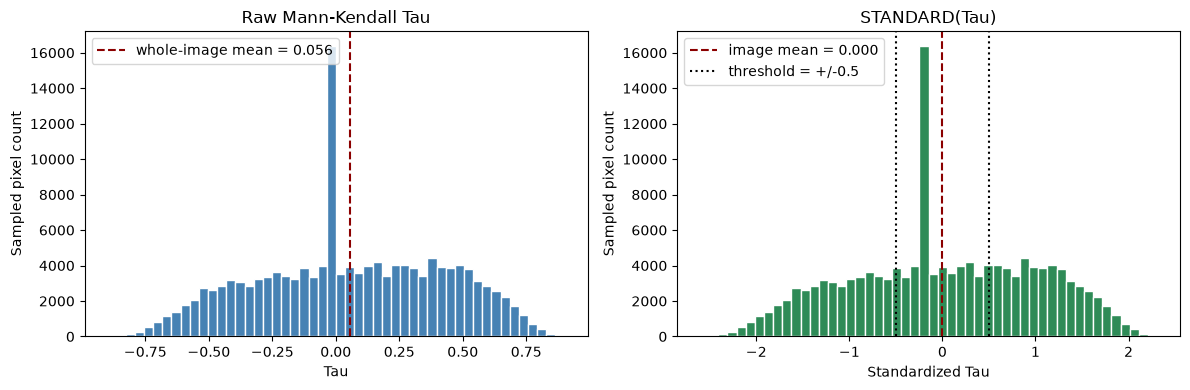

In [66]:
### Run Stage 5: review the standardized-Tau histogram and threshold reference

histogram_results = plot_tau_histogram(mk_results, zscore_threshold)

In [34]:
import numpy as np, rasterio
from pathlib import Path
main_workspace, metric_type = "./data", "edge"
std_path = Path(main_workspace)/"4_TS_and_TI"/"TS_zscore"/metric_type/f"{metric_type}_MK_tau_z.tif"

for thr in (0.3, 0.5, 0.75, 1.0):
    n=pos=neg=0
    with rasterio.open(std_path) as s:
        for _, w in s.block_windows(1):
            a=s.read(1,window=w,masked=True); v=np.ma.getdata(a)[~np.ma.getmaskarray(a)]
            n+=v.size; pos+=int((v>thr).sum()); neg+=int((v<-thr).sum())
    print(f"thr +/-{thr}: increasing {pos/n:5.1%} | stable {(n-pos-neg)/n:5.1%} | decreasing {neg/n:5.1%}")


thr +/-0.3: increasing 42.2% | stable 17.9% | decreasing 39.9%
thr +/-0.5: increasing 36.5% | stable 29.0% | decreasing 34.5%
thr +/-0.75: increasing 28.8% | stable 43.5% | decreasing 27.7%
thr +/-1.0: increasing 20.5% | stable 58.8% | decreasing 20.7%


## Output files

All outputs are under `D:/GitHub/typology/data/4_TS_and_TI/`:

- `TS/<metric>/`: `<metric>_raster_group_MK_tau.tif`. The input raster group is kept in memory; no group manifest or multiband time-series raster is saved.
- `TS_mask/<metric>_mask/`: one `<metric>_<year>_mask_nan.tif` per year. Each file is `1` where that year's input is NoData/NaN, and `0` where data exists; valid pixel values of zero remain valid. A separate mask is necessary because valid coverage can change annually; valid zero values remain data.
- `TS_zscore/<metric>/`: `<metric>_MK_tau_z.tif`, standardized from valid Tau cells using the image mean and population standard deviation (`N`). The TerrSet STANDARD description supplied specifies mean subtraction and division by standard deviation but does not state the divisor; `N` is the chosen interpretation. The editable `zscore_threshold` parameter is used only by the final histogram review, where it is drawn as `+/-` reference lines on the standardized-Tau distribution. The histogram only displays the threshold; it does not apply it, set central values to zero, or change Tau or STANDARD. The threshold-based classification itself happens in the downstream step, not in this notebook. The notebook writes one Tau raster and one standardized raster per selected metric; run it for area, edge, and pn to create those three outputs.

Pixels with fewer than 10 valid annual observations are NoData in the Tau output (stored as -9999 with NoData metadata). Valid Tau values of zero remain zero. The same NoData marker is preserved in the standardized-Tau output; internal calculations use NaN for missing values. The provided TerrSet note says at least 10 observations are required but does not specify whether TerrSet applies this rule pixel by pixel. The multiprocessing helper is created in the system temporary folder. Statistical significance Z/p and classification are not produced.

In [1]:
# checkig tau z score

import numpy as np, rasterio
from pathlib import Path

main_workspace = "./data"; metric_type = "edge"
std_path = Path(main_workspace)/"4_TS_and_TI"/"TS_zscore"/metric_type/f"{metric_type}_MK_tau_z.tif"

if not std_path.exists():
    print("Stage 4 output not found — run Stage 4 first.")
else:
    n = 0; mean = 0.0; m2 = 0.0
    with rasterio.open(std_path) as s:
        print("tiled:", s.is_tiled, "| block:", s.block_shapes[0])
        for _, win in s.block_windows(1):            # one 512-tile at a time
            a = s.read(1, window=win, masked=True)
            v = np.ma.getdata(a)[~np.ma.getmaskarray(a)].astype(np.float64)
            if v.size:
                d = v - mean; n += v.size; mean += d.sum()/n; m2 += ((v-mean)*d).sum()
    print("valid pixels      :", f"{n:,}")
    print("standardized mean :", f"{mean:.4f}   (~0 expected)")
    print("standardized std  :", f"{(m2/n)**0.5:.4f}   (~1 expected)")




tiled: True | block: (512, 512)
valid pixels      : 1,027,646,953
standardized mean : -0.0000   (~0 expected)
standardized std  : 1.0000   (~1 expected)
